In [1]:
import numpy as np
import numpy.ma as ma
from netCDF4 import Dataset
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import matplotlib.ticker as mticker
from matplotlib import colors
from matplotlib.ticker import FuncFormatter

import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors

import matplotlib.patches as mpatches
import cartopy
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.crs as ccrs

import iris
import iris.quickplot as qplt 
import iris.plot as iplt
iris.FUTURE.netcdf_promote=True
import iris.coord_categorisation

from matplotlib.path import Path
import matplotlib.ticker as ticker

/apps/developers/compilers/canopy3/2.1.3/1/bit-64/Canopy/edm/envs/User/lib/python3.5/site-packages/matplotlib/ticker.py:1693: UserWarning: Steps argument should be a sequence of numbers
increasing from 1 to 10, inclusive. Behavior with
values outside this range is undefined, and will
raise a ValueError in future versions of mpl.
  warnings.warn('Steps argument should be a sequence of numbers\n'


In [2]:
### Upload PI Annual
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path1 = '/nfs/hera1/ee22kvcs/work/nc/xpzed/datam/pd/'
path2 = '/nfs/hera1/ee22kvcs/KCM/'

models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_pi = ['tauuo_Omon_ACCESS-ESM1-5_piControl_r1i1p1f1_gn_100101-110012_reg_360x385_100yr_mean.nc',
                   'xpzed_pd_5021-5120_reg_360x385_100yr_mean.nc',
                   'tauuo_Omon_IPSL-CM6A-LR_piControl_r1i1p1f1_gn_375001-384912_100yr_mean_reg_360x385.nc',
                   'H0K_mm_6401_6500.codeUtau_100yr_means_reg_360x385.nc',
                   'tauuo_Omon_MIROC-ES2L_piControl_r1i1p1f2_gr1_225001-234912_100yr_mean_reg_360x385.nc',
                   'tauuo_Omon_NorESM1-F_piControl_r1i1p1f1_gn_160101-170012_100yr_mean_reg_360x385.nc',
                   'tauuo_Omon_NorESM2-LM_piControl_r1i1p4f1_gn_180001-189912_100yr_mean_reg_360x385.nc',
                  ]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauuo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'taux'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauuo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauuo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauuo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauuo'),
              ]

PI_models_ann = []
for i in range(np.size(models)):
    if i == 1:
        uploaded_cubes = iris.load_cube(path1+names_models_pi[i], constraints[i])
    elif i == 3:
        uploaded_cubes = iris.load_cube(path2+names_models_pi[i], constraints[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_pi[i], constraints[i])
    uploaded_cubes2 = iris.util.squeeze(uploaded_cubes)
    PI_models_ann.append(uploaded_cubes2)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [4]:
### Upload LIG Annual
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path1 = '/nfs/hera1/ee22kvcs/work/nc/xpzec/datam/pd/'
path2 = '/nfs/hera1/ee22kvcs/KCM/'

models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_lig = ['tau_x_Omon_ACCESS-ESM1-5_lig127k_1823_1923_reg_360x385_100yr_mean.nc',
                   'xpzec_pd_6651-6750_reg_360x385_100yr_mean.nc',
                   'tauuo_Omon_IPSL-CM6A-LR_lig127k_r1i1p1f1_gn_230001-239912_100yr_mean_reg_360x385.nc',
                   'E7C_mm_4901_5000.codeUtau_100yr_means_reg_360x385.nc',
                   'tauuo_Omon_MIROC-ES2L_lig127k_r1i1p1f2_gr1_330001-339912_100yr_mean_reg_360x385.nc',
                   'tauuo_Omon_NorESM1-F_lig127k_r1i1p1f1_gn_160101-170012_100yr_mean_reg_360x385.nc',
                   'tauuo_Omon_NorESM2-LM_lig127k_r1i1p1f1_gn_210101-220012_100yr_mean_reg_360x385.nc',
                  ]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'tau_x'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'taux'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauuo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauuo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauuo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauuo'),
              ]

LIG_models_ann = []
for i in range(np.size(models)):
    if i == 1:
        uploaded_cubes = iris.load_cube(path1+names_models_lig[i], constraints[i])
    elif i == 3:
        uploaded_cubes = iris.load_cube(path2+names_models_lig[i], constraints[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_lig[i], constraints[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    LIG_models_ann.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [5]:
### Mend MIROC-ES2L
PI_models_ann[4].data *= -1
LIG_models_ann[4].data *= -1

#### Annual MMM

In [6]:
### PI and LIG
sw_pi_ann = [cube.copy() for cube in PI_models_ann]
sw_lig_ann = [cube.copy() for cube in LIG_models_ann]

# Calculate MMM
MMM_pi_ann = sum([sw_pi_ann[i].data for i in range(np.size(sw_pi_ann))])/7
MMM_lig_ann = sum([sw_lig_ann[i].data for i in range(np.size(sw_lig_ann))])/7

# Convert to iris cubes
MMM_pi_ann_cube = sw_pi_ann[0].copy(data = MMM_pi_ann)
MMM_lig_ann_cube = sw_lig_ann[0].copy(data = MMM_lig_ann)

In [7]:
### Zonal means
### Models
PI_zmean_ann = [n.collapsed('longitude', iris.analysis.MEAN) for n in PI_models_ann]
LIG_zmean_ann = [n.collapsed('longitude', iris.analysis.MEAN) for n in LIG_models_ann]
### MMM
MMM_zmean_ann_pi = MMM_pi_ann_cube.collapsed('longitude', iris.analysis.MEAN)
MMM_zmean_ann_lig = MMM_lig_ann_cube.collapsed('longitude', iris.analysis.MEAN)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:988: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(self.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:1017: UserWarning: Collapsing a non-contiguous coordinate. Metadata may not be fully descriptive for 'longitude'.
  warnings.warn(msg.format(self.name()))


### Plots

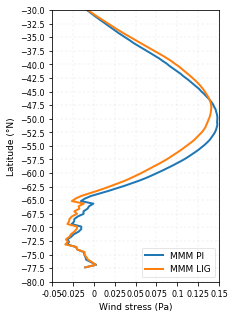

In [8]:
# Plot the Annual MMM
def clean_tick(x, pos):
    x = round(x, 6) + 0.0          # remove float noise and -0.0
    return '{:g}'.format(x)        # 0.150 -> 0.15, 0.000 -> 0

fig = plt.figure(figsize=(3, 5))
axes = []
for i in range(1):
    ax = fig.add_subplot(1, 1, i + 1)
    axes.append(ax)

for ax in axes:
    lat = MMM_zmean_ann_pi.coord('latitude').points
    pi_mmm = MMM_zmean_ann_pi.data.squeeze()
    lig_mmm = MMM_zmean_ann_lig.data.squeeze()
    
    ax.plot(pi_mmm, lat, label = 'MMM PI', linewidth = 2)
    ax.plot(lig_mmm, lat, label = 'MMM LIG', linewidth = 2)
    
    ax.set_xlabel('Wind stress (Pa)', size=9)
    ax.tick_params(axis='x', labelsize=8)
    ax.tick_params(axis='y', labelsize=8)
    ax.grid(True, linestyle=':', linewidth=0.2, color='gray', alpha=0.5)
    #ax.axvline(0, color='k', linewidth=1, linestyle='--')  # zero reference line
    
    ax.set_ylabel('Latitude (°N)', size=9)
    ax.set_ylim(-80, -30)
    ax.set_yticks(np.arange(-80, -30+2.5, 2.5))
    ax.set_xlim(-0.035, 0.15)
    ax.set_xticks(np.arange(-.05, .15+.025, .025))
    ax.xaxis.set_major_formatter(FuncFormatter(clean_tick))

    ax.legend(fontsize=9, loc='lower right', framealpha=0.5)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/tauuo_MMM_annual_corrected_v2.png', bbox_inches='tight', dpi=300, format='png')
plt.show()

/nfs/see-fs-01_users/mlzp121/.local/lib/python3.5/site-packages/numpy/ma/core.py:3337: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  _data[indx] = dval
/nfs/see-fs-01_users/mlzp121/.local/lib/python3.5/site-packages/numpy/ma/core.py:3340: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  _mask[indx] = mval


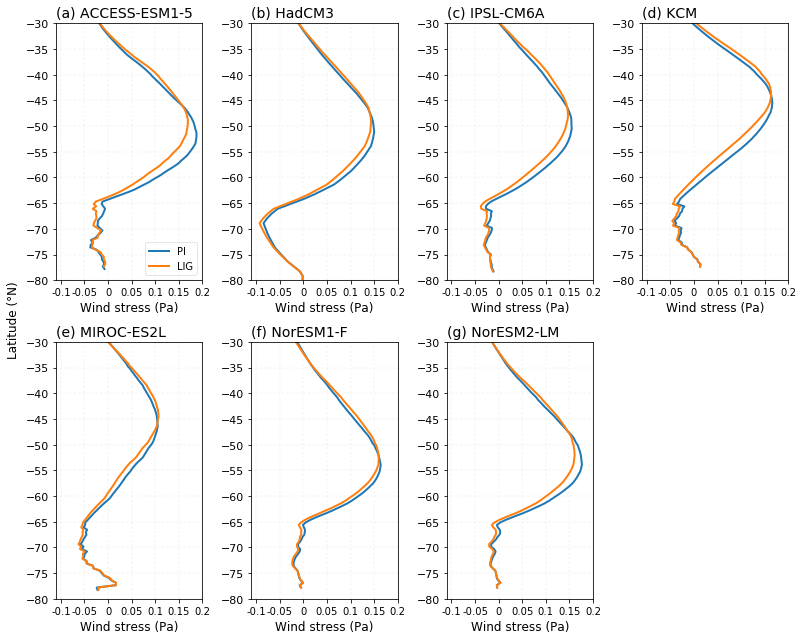

In [9]:
# Plot by model
fig = plt.figure(figsize=(11, 9))
axes = []

def clean_tick(x, pos):
    x = round(x, 6) + 0.0          # remove float noise and -0.0
    return '{:g}'.format(x)        # 0.150 -> 0.15, 0.000 -> 0

for i in range(7):
    ax = fig.add_subplot(2, 4, i + 1)
    axes.append(ax)

models = ['(a) ACCESS-ESM1-5', '(b) HadCM3', '(c) IPSL-CM6A', '(d) KCM', '(e) MIROC-ES2L', '(f) NorESM1-F', '(g) NorESM2-LM']

for ax, i in zip(axes, range(len(models))):
    
    lat = PI_zmean_ann[i].coord('latitude').points
    pi = PI_zmean_ann[i].data.squeeze()
    lig = LIG_zmean_ann[i].data.squeeze()
    
    ax.plot(pi, lat, label = 'PI', linewidth = 2)
    ax.plot(lig, lat, label = 'LIG', linewidth = 2)
    
    ax.set_title(models[i], fontsize=14, loc='left')
    ax.set_xlabel('Wind stress (Pa)', size=12)
    ax.tick_params(axis='x', labelsize=10)
    ax.tick_params(axis='y', labelsize=11)
    ax.grid(True, linestyle=':', linewidth=0.2, color='gray', alpha=0.5)
    
    ax.set_ylim(-80, -30)
    ax.set_yticks(np.arange(-80, -29, 5))
    ax.set_xlim(-0.11, 0.2)
    ax.set_xticks(np.arange(-.1, .2+.05, .05))
    ax.xaxis.set_major_formatter(FuncFormatter(clean_tick))
    
axes[0].legend(fontsize=10, loc='lower right', framealpha = 0.5)
plt.tight_layout()
fig.text(-0.01, 0.5, 'Latitude (°N)', va='center', rotation='vertical', fontsize=12)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/tauuo_annual_corrected_v2.png', bbox_inches='tight', dpi=300, format='png')
plt.show()